In [0]:

# Load the cleaned dataset for analytics

from pyspark.sql import functions as F

silver_df = spark.table("workspace.default.silver_secom_quality")

print("Dataset loaded:", silver_df.count(), "records")


Dataset loaded: 1567 records


In [0]:

# Count passing and failing semiconductor samples

quality_counts = (
    silver_df
    .groupBy("quality_label")
    .count()
    .orderBy("quality_label")
)

quality_counts.show()

# Calculate the defect rate
total_records = silver_df.count()

failed_records = silver_df.filter(
    F.col("quality_label") == 1
).count()

passed_records = silver_df.filter(
    F.col("quality_label") == -1
).count()

print("Total records:", total_records)
print("Passed records:", passed_records)
print("Failed records:", failed_records)
print("Defect rate:", round(failed_records / total_records * 100, 2), "%")


+-------------+-----+
|quality_label|count|
+-------------+-----+
|           -1| 1463|
|            1|  104|
+-------------+-----+

Total records: 1567
Passed records: 1463
Failed records: 104
Defect rate: 6.64 %


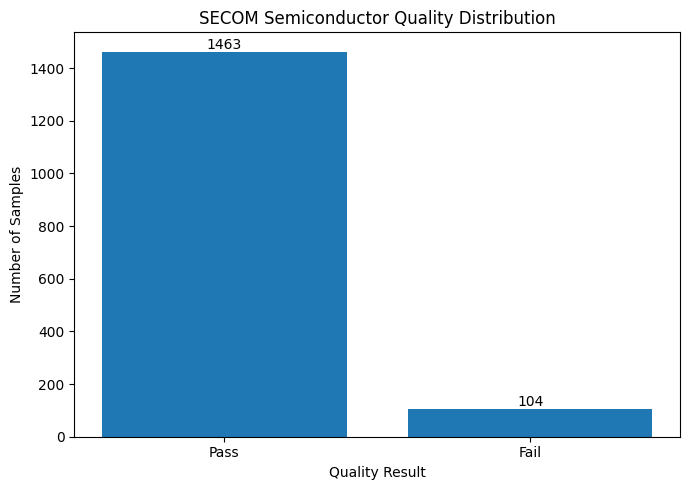

In [0]:

import matplotlib.pyplot as plt

labels = ["Pass", "Fail"]
counts = [passed_records, failed_records]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, counts)

plt.title("SECOM Semiconductor Quality Distribution")
plt.xlabel("Quality Result")
plt.ylabel("Number of Samples")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


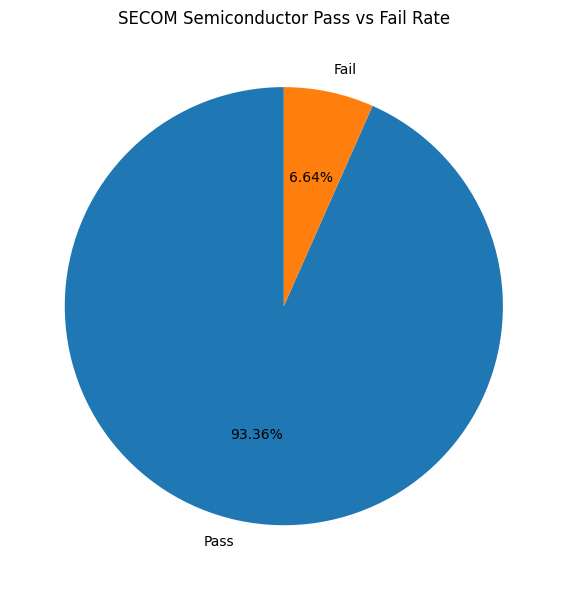

In [0]:

plt.figure(figsize=(6, 6))

plt.pie(
    counts,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("SECOM Semiconductor Pass vs Fail Rate")
plt.tight_layout()
plt.show()


In [0]:

# Create a quality summary table

quality_summary = spark.createDataFrame(
    [
        ("Total Samples", total_records),
        ("Passed Samples", passed_records),
        ("Failed Samples", failed_records),
    ],
    ["Metric", "Count"]
)

quality_summary.show()

print("Pass rate:", round(passed_records / total_records * 100, 2), "%")
print("Defect rate:", round(failed_records / total_records * 100, 2), "%")


+--------------+-----+
|        Metric|Count|
+--------------+-----+
| Total Samples| 1567|
|Passed Samples| 1463|
|Failed Samples|  104|
+--------------+-----+

Pass rate: 93.36 %
Defect rate: 6.64 %


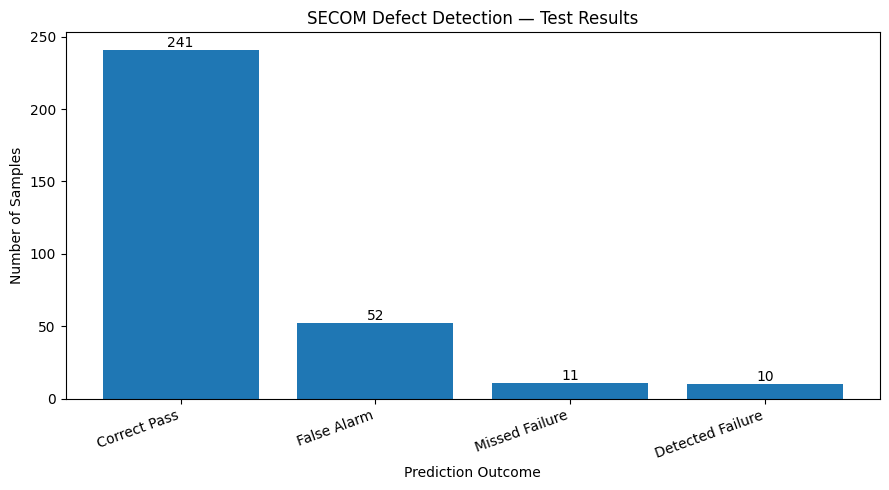

In [0]:

# Visualize the model's test-set outcomes

import matplotlib.pyplot as plt

outcome_labels = [
    "Correct Pass",
    "False Alarm",
    "Missed Failure",
    "Detected Failure"
]

outcome_counts = [241, 52, 11, 10]

plt.figure(figsize=(9, 5))
bars = plt.bar(outcome_labels, outcome_counts)

plt.title("SECOM Defect Detection — Test Results")
plt.xlabel("Prediction Outcome")
plt.ylabel("Number of Samples")
plt.xticks(rotation=20, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [0]:

# Verify Bronze, Silver, and Gold tables

table_names = [
    "workspace.default.bronze_secom_measurements_raw",
    "workspace.default.bronze_secom_labels_raw",
    "workspace.default.silver_secom_quality",
    "workspace.default.gold_secom_defect_predictions"
]

for table_name in table_names:
    count = spark.table(table_name).count()
    print(f"{table_name}: {count} rows")


workspace.default.bronze_secom_measurements_raw: 1567 rows
workspace.default.bronze_secom_labels_raw: 1567 rows
workspace.default.silver_secom_quality: 1567 rows
workspace.default.gold_secom_defect_predictions: 314 rows
